# AirFare Prediction
    Using some data about avaition industry's customers, we shall predict what the averge price could be for any given route.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
airfares = pd.read_csv('http://users.stat.ufl.edu/~winner/data/airq402.dat',sep='\s+',header=None)

In [3]:
airfares

,0,1,2,3,4,5,6,7,8,9,10
0,CAK,ATL,114.47,528,424.56,FL,70.19,111.03,FL,70.19,111.03
1,CAK,MCO,122.47,860,276.84,FL,75.10,123.09,DL,17.23,118.94
2,ALB,ATL,214.42,852,215.76,DL,78.89,223.98,CO,2.77,167.12
3,ALB,BWI,69.40,288,606.84,WN,96.97,68.86,WN,96.97,68.86
4,ALB,ORD,158.13,723,313.04,UA,39.79,161.36,WN,15.34,145.42
...,...,...,...,...,...,...,...,...,...,...,...
995,SYR,TPA,136.16,1104,184.34,US,33.37,135.82,DL,28.65,118.51
996,TLH,TPA,83.28,200,232.71,FL,99.57,82.55,FL,99.57,82.55
997,TPA,IAD,159.97,814,843.80,US,46.19,159.65,DL,13.89,159.02
998,TPA,PBI,73.57,174,214.45,WN,99.74,73.44,WN,99.74,73.44


#### Data Description

    City1 - 1st city of route   
    City2 - 2nd city of route
    Average Fare - Average price of the route
    Distance - Distance between cities
    Average weekly passengers - Average weekly passengers travelling in the route
    market leading airline - Market Leading airline(not necessarily the costliest)
    market share - Market share of this airline
    Average fare - Market leading airline avg. fare
    Low price airline - Low price airline for that route
    market share - Market share for the low price airline
    price - Low price Airline avg. fare
    
    
    Average Fare will be the dependent variable and everything else will be independent

In [4]:
airfares.columns = ['City1','City2','Average Fare','Distance','Average weekly passengers','market leading airline',
                    'market share','LeadingAirline_avgFare','Low price airline','market share','LowPriceAirline_avgFare']
airfares

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
0,CAK,ATL,114.47,528,424.56,FL,70.19,111.03,FL,70.19,111.03
1,CAK,MCO,122.47,860,276.84,FL,75.10,123.09,DL,17.23,118.94
2,ALB,ATL,214.42,852,215.76,DL,78.89,223.98,CO,2.77,167.12
3,ALB,BWI,69.40,288,606.84,WN,96.97,68.86,WN,96.97,68.86
4,ALB,ORD,158.13,723,313.04,UA,39.79,161.36,WN,15.34,145.42
...,...,...,...,...,...,...,...,...,...,...,...
995,SYR,TPA,136.16,1104,184.34,US,33.37,135.82,DL,28.65,118.51
996,TLH,TPA,83.28,200,232.71,FL,99.57,82.55,FL,99.57,82.55
997,TPA,IAD,159.97,814,843.80,US,46.19,159.65,DL,13.89,159.02
998,TPA,PBI,73.57,174,214.45,WN,99.74,73.44,WN,99.74,73.44


In [5]:
airfares.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
City1                        1000 non-null object
City2                        1000 non-null object
Average Fare                 1000 non-null float64
Distance                     1000 non-null int64
Average weekly passengers    1000 non-null float64
market leading airline       1000 non-null object
market share                 1000 non-null float64
LeadingAirline_avgFare       1000 non-null float64
Low price airline            1000 non-null object
market share                 1000 non-null float64
LowPriceAirline_avgFare      1000 non-null float64
dtypes: float64(6), int64(1), object(4)
memory usage: 86.1+ KB


    No null values at all and all features seem to have relevant datatypes

In [8]:
airfares.describe()

,Average Fare,Distance,Average weekly passengers,market share,LeadingAirline_avgFare,market share,LowPriceAirline_avgFare
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,163.37542,1056.973000,672.279140,60.128590,166.64756,34.551480,143.193090
std,55.36547,643.203251,766.519254,19.367779,62.66014,27.096999,47.229184
min,50.52000,108.000000,181.410000,17.680000,50.52000,1.060000,49.610000
25%,125.97500,553.500000,257.197500,46.510000,124.08500,13.195000,113.767500
50%,161.34500,919.000000,404.780000,59.240000,161.40000,26.140000,137.825000
75%,197.39250,1452.500000,769.912500,73.510000,202.97750,52.972500,168.530000
max,401.23000,2724.000000,8950.760000,100.000000,490.03000,100.000000,387.940000


In [9]:
airfares.describe(include='O')

,City1,City2,market leading airline,Low price airline
count,1000,1000,1000,1000
unique,90,85,16,19
top,ATL,TPA,WN,WN
freq,64,46,257,230


    WN seems like the most preferred airline and clearly it is also a low priced airline. There are 27 routes where WN has been the market leader despite not being the Low price airline

In [33]:
airfares.duplicated().sum()

0

### The benchmark
    
        Let's run the most simplest model to see how well we will be able to predict the prices. Since the problem is regression, we shall use metrics like rmse,mae

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder

In [34]:
airfares_org = airfares.copy(deep=True)

In [11]:
airfares_copy = airfares.copy(deep=True)
le = LabelEncoder()
for col in airfares_copy.columns[airfares.dtypes.values == 'O']:
    airfares_copy[col] = le.fit_transform(airfares_copy[col])
    
airfares_copy.head()

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
0,16,0,114.47,528,424.56,6,70.19,111.03,8,70.19,111.03
1,16,40,122.47,860,276.84,6,75.10,123.09,6,17.23,118.94
2,2,0,214.42,852,215.76,4,78.89,223.98,5,2.77,167.12
3,2,7,69.40,288,606.84,14,96.97,68.86,17,96.97,68.86
4,2,52,158.13,723,313.04,12,39.79,161.36,17,15.34,145.42


In [12]:
X_train, X_test, y_train, y_test = train_test_split(airfares_copy.drop(labels=['Average Fare'],axis=1),airfares_copy['Average Fare'],
                                                   test_size=0.15)

lr_benchmark = LinearRegression()
lr_benchmark.fit(X_train,y_train)
pred = lr_benchmark.predict(X_test)


print(f'Mean Squared Error: {metrics.mean_squared_error(pred,y_test)}')
print(f'Mean absolute Error: {metrics.mean_absolute_error(pred,y_test)}')

Mean Squared Error: 72.71967155848647
Mean absolute Error: 6.128405999644338


#### Possible methods to improveme score
    - Tune the existing model
    - Apply transformations
    - Use more complex models
    - Perform feature engineering/ delete columns with least information
    - Try Cross-validation
    - Identify optimal values over a serach space of parameters(GridSearch/RandomSearch)

    We shall now try to improve these scores with more analysis

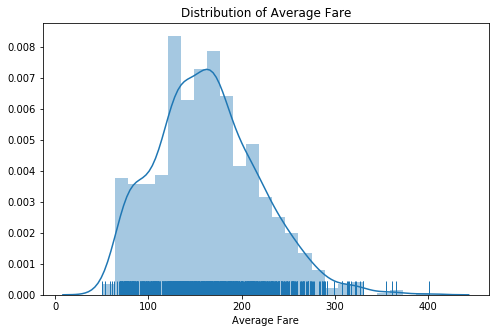

In [13]:
plt.figure(figsize=(8,5))
sns.distplot(airfares['Average Fare'],rug=True)
plt.title('Distribution of Average Fare')
plt.show()

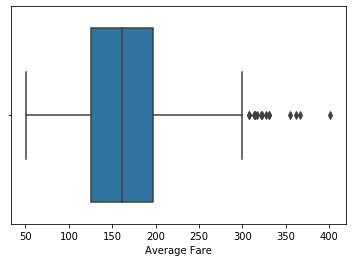

In [14]:
sns.boxplot(airfares['Average Fare'])

    Let's zoom in to the values that aren't outliers

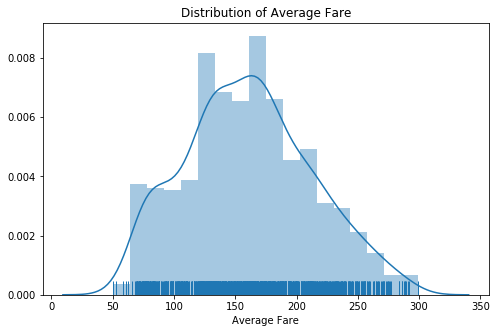

In [15]:
plt.figure(figsize=(8,5))
sns.distplot(airfares[airfares['Average Fare']<=300]['Average Fare'],rug=True)
plt.title('Distribution of Average Fare')
plt.show()

    Let's look at the outliers

In [16]:
airfares_out = airfares[airfares['Average Fare']>300]
airfares_out

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
197,BOS,LAX,314.01,2611,1259.02,AA,38.28,345.48,AA,38.28,345.48
212,BOS,SAN,307.42,2588,355.21,AA,46.69,316.03,HP,11.84,288.50
213,BOS,SFO,355.15,2704,1270.00,UA,45.88,410.14,AA,23.38,387.94
328,CVG,LAX,321.40,1900,251.08,DL,75.67,343.53,NW,4.02,198.06
607,IAH,SFO,313.22,1656,467.60,CO,60.76,354.08,HP,10.34,212.29
709,LAX,MIA,330.28,2342,680.86,AA,54.42,353.23,HP,11.95,215.30
714,LAX,LGA,317.20,2475,5680.65,AA,29.35,382.59,CO,18.13,276.99
737,LAX,IAD,361.57,2311,1379.45,UA,51.73,419.95,AA,24.46,355.48
760,MIA,SFO,327.45,2585,404.78,AA,47.04,366.46,UA,28.22,316.15
836,LGA,SAN,314.66,2446,1150.10,CO,30.79,362.41,HP,15.37,243.25


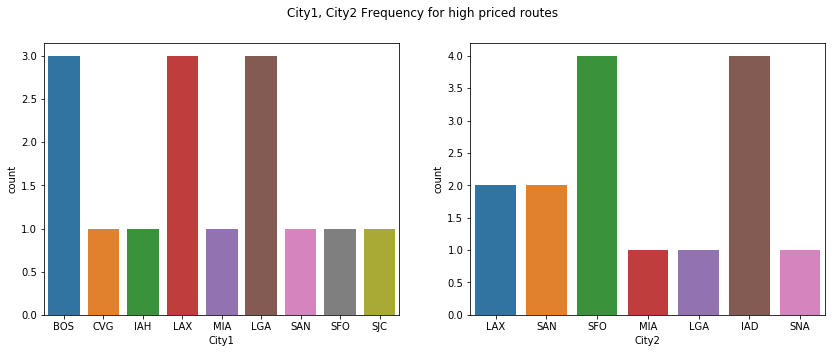

In [17]:
fig, axs = plt.subplots(nrows=1,ncols=2,figsize=(14,5))

plt.suptitle('City1, City2 Frequency for high priced routes')
for ax,col in zip(axs,['City1','City2']):
    sns.countplot(airfares_out[col],ax=ax)

    Most of the cities are common for both 1 and 2. There are a couple of them aren't common as well. Let's look at all cities that have a part in avg. high priced routes

In [31]:
print('Common cities in City1 and City2: ',set(airfares_out['City1']).intersection(set(airfares_out['City2'])))
print('Cities not repeated in City2: ',set(airfares_out['City1']).difference(set(airfares_out['City2'])))
print('Cities not repeated in City1: ',set(airfares_out['City2']).difference(set(airfares_out['City1'])))

Common cities in City1 and City2:  {'LGA', 'SAN', 'SFO', 'MIA', 'LAX'}
Cities not repeated in City2:  {'SJC', 'BOS', 'IAH', 'CVG'}
Cities not repeated in City1:  {'SNA', 'IAD'}


    The common cities mean travelling to or from any of them imply a likely high fare
    
    Now will be a time to answer a good question, are all the routes only listed one side? i.e, is there no route written City1 - City2 and another entry for the same duo but the roles reversed -> former City1 is now City2 and former City2 now City1

In [57]:
def check_round_trip(row):
    for record in range(len(airfares)):
        if (row['City1'] == airfares.loc[record,'City2']) and (row['City2'] == airfares.loc[record,'City1']):
            return True

airfares['vice_versa_mentioned'] = airfares.apply(check_round_trip,axis=1)

    Though this code had given us what we want, this is not a good way to process data. More often than not, the number of rows will be huge and hence the time taken will also be too much

In [58]:
airfares['vice_versa_mentioned'].sum()

0

    So, there are no round trips mentioned in the data

In [74]:
airfares_out[airfares_out['City1'].isin(['SJC', 'BOS', 'IAH', 'CVG'])]

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
197,BOS,LAX,314.01,2611,1259.02,AA,38.28,345.48,AA,38.28,345.48
212,BOS,SAN,307.42,2588,355.21,AA,46.69,316.03,HP,11.84,288.50
213,BOS,SFO,355.15,2704,1270.00,UA,45.88,410.14,AA,23.38,387.94
328,CVG,LAX,321.40,1900,251.08,DL,75.67,343.53,NW,4.02,198.06
607,IAH,SFO,313.22,1656,467.60,CO,60.76,354.08,HP,10.34,212.29
989,SJC,IAD,322.83,2424,229.02,UA,37.01,408.10,TZ,13.57,172.45


In [75]:
airfares_out[airfares_out['City2'].isin(['SNA', 'IAD'])]

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share,LeadingAirline_avgFare,Low price airline,market share,LowPriceAirline_avgFare
737,LAX,IAD,361.57,2311,1379.45,UA,51.73,419.95,AA,24.46,355.48
839,LGA,SNA,308.08,2454,590.54,CO,51.97,333.12,UA,12.58,273.63
981,SAN,IAD,330.21,2276,582.17,UA,42.55,440.35,AA,26.97,241.30
985,SFO,IAD,401.23,2442,955.65,UA,64.45,490.03,TZ,3.78,182.66
989,SJC,IAD,322.83,2424,229.02,UA,37.01,408.10,TZ,13.57,172.45


    Let's plot all these in a map to see the difference between outliers and regular ones clearly. We will now extract the airport codes, their cities from https://www.ccra.com/airport-codes/ using requests and beautiful soup

In [80]:
import requests
from bs4 import BeautifulSoup

In [82]:
resp = requests.get('https://www.ccra.com/airport-codes/')
bs = BeautifulSoup(resp.content,'html.parser')

In [85]:
airport_codes_table = bs.find('table',attrs={'id':"tablepress-40", 'class':"tablepress tablepress-id-40"})

In [153]:
cities = airport_codes_table.find_all('td',attrs={'class':'column-1'})
country = airport_codes_table.find_all('td',attrs={'class':'column-2'})
airport_codes = airport_codes_table.find_all('td',attrs={'class':'column-3'})

In [159]:
codes = pd.DataFrame({'City':cities,'Country':country,'Code':airport_codes})
codes.head()

,City,Country,Code
0,[Aalborg],[Denmark],[AAL]
1,[Aalesund],[Norway],[AES]
2,[Aarhus],[Denmark],[AAR]
3,"[Abbotsford, BC]",[Canada],[YXX]
4,"[Abbotsford, BC ]",[Canada ],[YXX]


    Though this looks like a perfect string format, behind the scenes all the entries are HTML tags whose text is being displayed

In [160]:
from sklearn.base import TransformerMixin, BaseEstimator
from unicodedata import normalize
import re

def clean_helper(val):
    return normalize('NFKD',val.get_text()).strip()

class extract_airport_details(BaseEstimator,TransformerMixin):
    def __init__(self):
        pass
    
    def fit(self,X,y=None):
        
        return self
    
    def transform(self,X,y=None):
        for col in X.columns:
            X[col] = X[col].apply(clean_helper)
            
        X = X[X['Country']=='USA']
        return X
    

airport_codes_clean = extract_airport_details().fit_transform(codes)

In [164]:
airport_codes_clean.reset_index(drop=True,inplace=True)
airport_codes_clean

,City,Country,Code
0,"Aberdeen, SD",USA,ABR
1,"Abilene, TX",USA,ABI
2,"Akron, OH",USA,CAK
3,"Alamosa, CO",USA,ALS
4,"Albany, GA",USA,ABY
...,...,...,...
441,"Worland, WY",USA,WRL
442,"Wrangell, AK",USA,WRG
443,"Yakima, WA",USA,YKM
444,"Yakutat, AK",USA,YAK


    The helper function needs a normalization because after analysing the extracted data, we've noticed that '\xa0' exists along with the string USA. That string represents a space in the latin which isn't directly converted to regular space(utf-8). So we had to explicitly state that we want to normalize(function from unicodedata package) it to how we need it

    Let's now take a minute to snitize our code, we have created too many variables till now. Let's remove what's not necessary

In [166]:
del(cities)
del(country)
del(airport_codes)
del(airport_codes_table)
del(bs)
del(resp)

In [437]:
cols = ['AirportID','Name','City','Country','IATA','ICAO','Latitude','Longitude','Altitude','Timezone','DST','Tz','Type','Source']
airports_info = pd.read_csv('https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat',names=cols)

In [438]:
airports_info

,AirportID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz,Type,Source
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998,5282,10,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001,20,10,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005,5388,10,U,Pacific/Port_Moresby,airport,OurAirports
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977,239,10,U,Pacific/Port_Moresby,airport,OurAirports
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001,146,10,U,Pacific/Port_Moresby,airport,OurAirports
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7693,14106,Rogachyovo Air Base,Belaya,Russia,\N,ULDA,71.616699,52.478298,272,\N,\N,\N,airport,OurAirports
7694,14107,Ulan-Ude East Airport,Ulan Ude,Russia,\N,XIUW,51.849998,107.737999,1670,\N,\N,\N,airport,OurAirports
7695,14108,Krechevitsy Air Base,Novgorod,Russia,\N,ULLK,58.625000,31.385000,85,\N,\N,\N,airport,OurAirports
7696,14109,Desierto de Atacama Airport,Copiapo,Chile,CPO,SCAT,-27.261200,-70.779198,670,\N,\N,\N,airport,OurAirports


In [448]:
us_airports = airports_info[airports_info['Country']=='United States']
us_airports.head()

,AirportID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz,Type,Source
3212,3411,Barter Island LRRS Airport,Barter Island,United States,BTI,PABA,70.134003,-143.582001,2,-9,A,America/Anchorage,airport,OurAirports
3213,3412,Wainwright Air Station,Fort Wainwright,United States,\N,PAWT,70.613403,-159.860001,35,-9,A,America/Anchorage,airport,OurAirports
3214,3413,Cape Lisburne LRRS Airport,Cape Lisburne,United States,LUR,PALU,68.875099,-166.110001,16,-9,A,America/Anchorage,airport,OurAirports
3215,3414,Point Lay LRRS Airport,Point Lay,United States,PIZ,PPIZ,69.732903,-163.005005,22,-9,A,America/Anchorage,airport,OurAirports
3216,3415,Hilo International Airport,Hilo,United States,ITO,PHTO,19.721399,-155.048004,38,-10,N,Pacific/Honolulu,airport,OurAirports


In [452]:
codes_map = dict(zip(us_airports['IATA'],zip(us_airports['Latitude'],us_airports['Longitude'])))

In [454]:
get_coord = lambda val: codes_map[val]
airfares['City1_coord'] = airfares['City1'].apply(get_coord)
airfares['City2_coord'] = airfares['City2'].apply(get_coord)

In [462]:
def sep_lat_long(row):
    return row['City1_coord'][0],row['City1_coord'][1],row['City2_coord'][0],row['City2_coord'][1]

airfares[['City1_lat','City1_long','City2_lat','City2_long']] = airfares.apply()

SyntaxError: invalid syntax (<ipython-input-462-88ab9a4d8e35>, line 2)

In [446]:
airfares.head()

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share_la,LeadingAirline_avgFare,Low price airline,market share_lpa,LowPriceAirline_avgFare,vice_versa_mentioned
0,CAK,ATL,114.47,528,424.56,FL,70.19,111.03,FL,70.19,111.03,None
1,CAK,MCO,122.47,860,276.84,FL,75.10,123.09,DL,17.23,118.94,None
2,ALB,ATL,214.42,852,215.76,DL,78.89,223.98,CO,2.77,167.12,None
3,ALB,BWI,69.40,288,606.84,WN,96.97,68.86,WN,96.97,68.86,None
4,ALB,ORD,158.13,723,313.04,UA,39.79,161.36,WN,15.34,145.42,None


In [251]:
gn = geocoders.GeoNames(username='mani16')
gn.geocode('Aberdeen, SD')

GeocoderAuthenticationFailure: Non-successful status code 401

In [216]:
obj_cols

['City1',
 'City2',
 'market leading airline',
 'Low price airline',
 'vice_versa_mentioned']

['City1',
 'City2',
 'market leading airline',
 'Low price airline',
 'vice_versa_mentioned']

In [191]:
#renamming market share for leading airline(la) and for low priced(lpa)
airfares.columns = ['City1','City2','Average Fare','Distance','Average weekly passengers','market leading airline',
                    'market share_la','LeadingAirline_avgFare','Low price airline','market share_lpa',
                    'LowPriceAirline_avgFare','vice_versa_mentioned']

obj_cols = list(airfares.describe(include='O').columns)
num_cols = list(airfares.describe(exclude='O').columns)

In [220]:
obj_cols

['City1',
 'City2',
 'market leading airline',
 'Low price airline',
 'vice_versa_mentioned']

In [221]:
obj_cols.pop()

'vice_versa_mentioned'

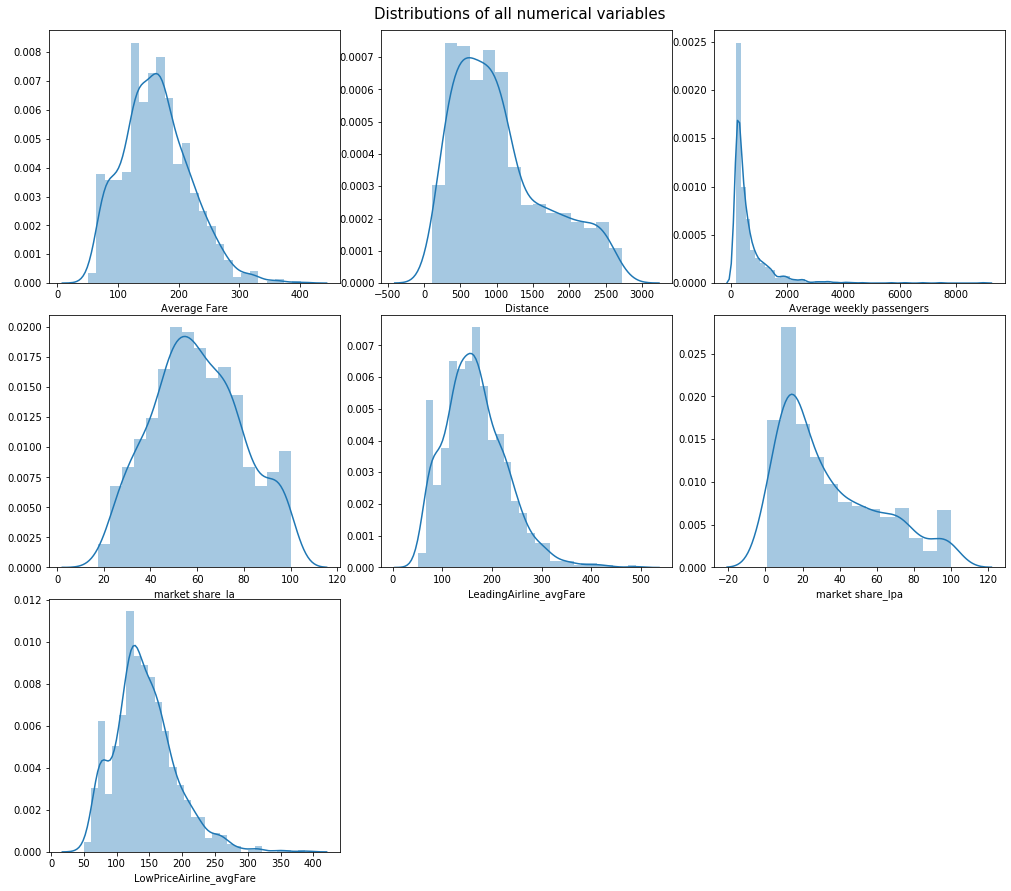

In [215]:
r = int(np.ceil(len(num_cols)/3))
fig, axs = plt.subplots(r,3,figsize=(14,r*4))
axs = axs.flatten()
axs[-1].axis('off')
axs[-2].axis('off')

plt.tight_layout()
plt.suptitle('Distributions of all numerical variables',y=1.01,fontsize=15)
for col,ax in zip(num_cols,axs):
    sns.distplot(airfares[col],ax=ax)


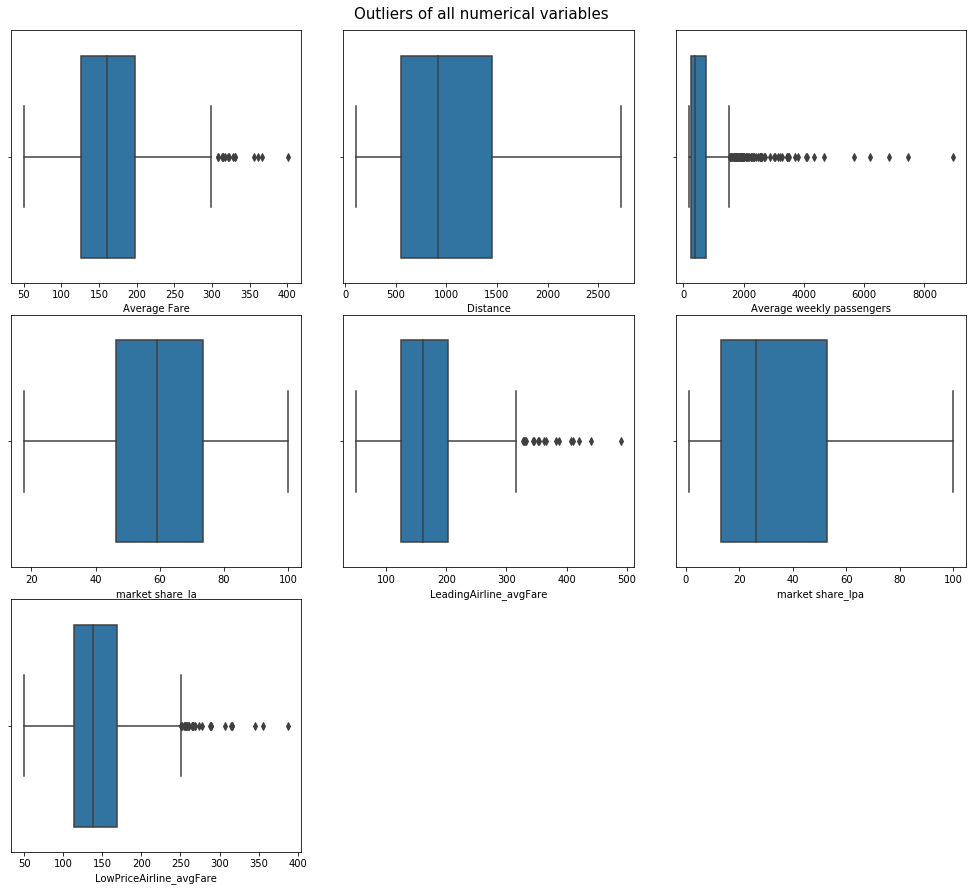

In [217]:
r = int(np.ceil(len(num_cols)/3))
fig, axs = plt.subplots(r,3,figsize=(14,r*4))
axs = axs.flatten()
axs[-1].axis('off')
axs[-2].axis('off')

plt.tight_layout()
plt.suptitle('Outliers of all numerical variables',y=1.01,fontsize=15)
for col,ax in zip(num_cols,axs):
    sns.boxplot(airfares[col],ax=ax)

In [218]:
airfares_avg_pass_out = airfares[airfares['Average weekly passengers']>1700]
airfares_avg_pass_out

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share_la,LeadingAirline_avgFare,Low price airline,market share_lpa,LowPriceAirline_avgFare,vice_versa_mentioned
32,ATL,BOS,156.55,946,1834.34,DL,75.26,163.05,FL,16.29,128.51,None
35,ATL,ORD,146.06,606,2885.76,DL,40.28,161.88,FL,26.08,111.32,None
39,ATL,DFW,147.50,732,2358.04,DL,55.36,152.80,AA,33.45,143.65,None
63,ATL,LGA,150.38,761,6185.43,DL,64.65,159.12,FL,16.55,124.12,None
71,ATL,PHL,130.36,665,1995.43,DL,53.12,138.50,FL,13.78,114.65,None
...,...,...,...,...,...,...,...,...,...,...,...,...
877,MCO,PHL,125.32,861,1990.21,US,65.64,124.13,US,65.64,124.13,None
918,PHX,SEA,132.19,1107,1774.34,AS,53.24,125.27,AS,53.24,125.27,None
953,SMF,SAN,80.81,480,2066.73,WN,96.57,80.53,WN,96.57,80.53,None
977,SAN,SJC,82.34,417,2176.19,WN,71.53,83.52,AA,26.94,79.37,None


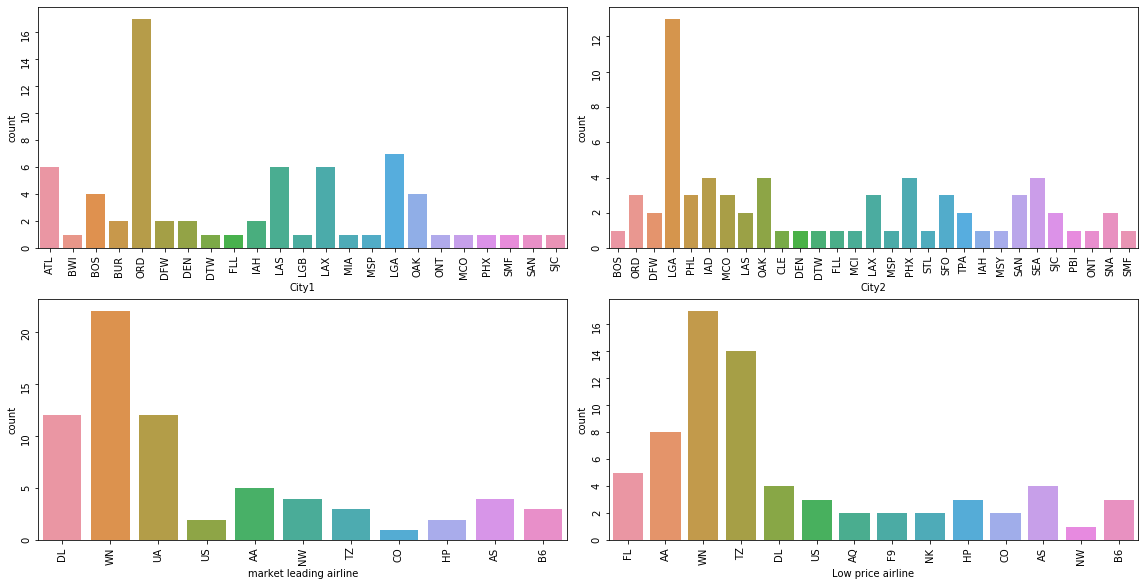

In [226]:
fig, axs = plt.subplots(2,2,figsize=(16,8))
axs = axs.flatten()


plt.tight_layout(h_pad=3)
for col, ax in zip(obj_cols,axs):
    sns.countplot(airfares_avg_pass_out[col],ax=ax)
    ax.tick_params(labelrotation=90)

    WN which is also the low cost airline for lots of routes is one of the leading airlines in many routes. Surely, WN has good dominance in the market
    
    ORD and LGA are the airports that are most busiest. Looks like they are some major centers

In [231]:
airport_codes_clean[airport_codes_clean['Code'].isin(['ORD','LGA'])]

,City,Country,Code
69,"Chicago, IL",USA,ORD
289,"New York, NY",USA,LGA


    Indeed, they are chicago and New York airports. They are expected to be busy

In [239]:
airfares_avg_pass_out[(airfares_avg_pass_out['City1']=='ORD') | (airfares_avg_pass_out['City2']=='LGA')]

,City1,City2,Average Fare,Distance,Average weekly passengers,market leading airline,market share_la,LeadingAirline_avgFare,Low price airline,market share_lpa,LowPriceAirline_avgFare,vice_versa_mentioned
63,ATL,LGA,150.38,761,6185.43,DL,64.65,159.12,FL,16.55,124.12,None
203,BOS,LGA,128.94,200,4662.82,DL,45.94,113.50,DL,45.94,113.50,None
260,ORD,CLE,94.32,316,1946.63,WN,37.46,74.16,WN,37.46,74.16,None
262,ORD,DFW,190.85,802,2621.63,AA,60.96,200.49,TZ,16.44,137.18,None
264,ORD,DEN,154.27,895,2353.15,UA,54.05,170.74,TZ,18.49,124.32,None
266,ORD,DTW,92.55,235,2262.71,NW,39.95,91.53,WN,23.07,81.63,None
268,ORD,FLL,135.72,1182,2240.65,TZ,24.41,109.07,TZ,24.41,109.07,None
277,ORD,MCI,77.80,405,1912.93,WN,51.06,75.07,WN,51.06,75.07,None
278,ORD,LAS,132.86,1521,3149.13,UA,23.04,152.91,TZ,21.09,118.86,None
281,ORD,LAX,167.07,1750,4120.00,UA,39.15,182.31,TZ,17.10,129.23,None


    From the above table we can infer a lot of information. To start, there's a snippet that hints of no linear correlation between fields like average fare, distance, average passengers. Moreover, this might even mean better chance of correlation between the route and fare

In [229]:
airfares_avg_pass_out.describe()

,Average Fare,Distance,Average weekly passengers,market share_la,LeadingAirline_avgFare,market share_lpa,LowPriceAirline_avgFare
count,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000
mean,139.427429,859.542857,2799.654143,57.319714,141.971714,37.167000,120.190714
std,59.963217,629.303219,1403.729092,20.525786,69.666287,27.163842,50.954053
min,62.880000,200.000000,1714.450000,23.040000,60.310000,2.270000,49.610000
25%,87.652500,363.250000,1951.572500,40.345000,84.930000,15.435000,80.805000
50%,131.920000,705.000000,2306.570000,56.545000,124.700000,25.765000,114.500000
75%,166.145000,1065.750000,3122.552500,70.607500,170.145000,55.347500,130.032500
max,365.930000,2586.000000,8950.760000,99.610000,386.700000,99.610000,315.610000


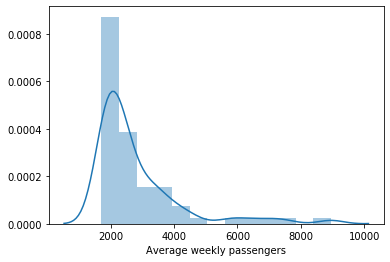

In [230]:
sns.distplot(airfares_avg_pass_out['Average weekly passengers'])

    These are all outliers in the number of passengers, even in them 2000-2600 is somewhat more common than the others. Higher numbers though present are only very few in frequency. However, we can't cap it or perform any operations to modify the outliers since they are all valid

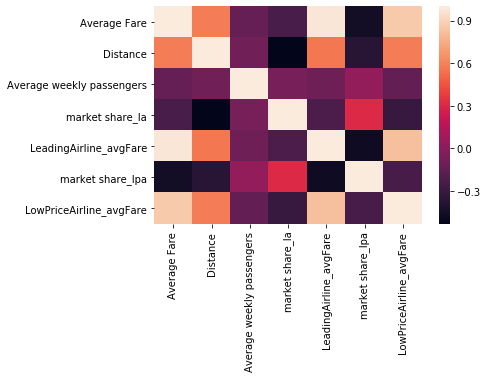

In [240]:
sns.heatmap(airfares.corr())

    Let's now get the data ready to make predictive models. We shall consider aspects like the transformations required, creating an efficient pipeline including the predictive models themselves.
    
     One thing we need to remember is the scale of numerical features is not consistent

In [334]:
X_train, X_test, y_train, y_test = train_test_split(airfares.drop(labels=['vice_versa_mentioned','Average Fare'],axis=1),airfares_copy['Average Fare'],
                                                   test_size=0.15)

In [287]:
cat_features = list()
num_features = list()
for col, tp in airfares.drop(labels=['vice_versa_mentioned','Average Fare'],axis=1).dtypes.iteritems():
    if tp == 'O':
        cat_features.append(col)
    else:
        num_features.append(col)

In [293]:
all_airports = list(set(airfares['City1']).union(airfares['City2']))
all_airlines = list(set(airfares['market leading airline']).union(airfares['Low price airline']))

In [264]:
from category_encoders import HashingEncoder,BinaryEncoder
from sklearn_features.transformers import DataFrameSelector

In [257]:
he_airports, he_airlines = HashingEncoder(), BinaryEncoder()
he_airports.fit(list(all_airports))
he_airlines.fit(list(all_airlines))

BinaryEncoder(cols=None, drop_invariant=False, handle_missing='value',
              handle_unknown='value', mapping=None, return_df=True, verbose=0)

In [346]:
class transform_to_encoding(BaseEstimator,TransformerMixin):
    '''Class to encode and transform City1, City2, market leading airline and Low price airline from the dataset using the 
    encoders provided. The encoders fit the list of all values of airports and airlines. This is done because there are names
    that aren't repeated in Cities, likewise for airlines as well.
    If encoders are applied seperately, that might cause inconsistencies in the encoding of repeated values'''
    def __init__(self,encoder):
        self.encoder = encoder
        
    
    def fit(self, X, y = None):
        '''self.encoder_cities.fit(all_airports)
        self.encoder_airlines.fit(all_airlines)'''
        self.encoder.fit(X)
        return self
    
    def transform(self, X, y = None):
        '''self.encoder_cities.transform(X['City1'])
        self.encoder_cities.transform(X['City2'].values)
        self.encoder_airlines.transform(X['market leading airline'].values)
        self.encoder_airlines.transform(X['Low price airline'].values)'''
        
        
        return self.encoder.transform(X)

In [331]:
from sklearn.pipeline import Pipeline,FeatureUnion
from sklearn.preprocessing import StandardScaler

In [347]:
cat_pipeline = Pipeline([('select cat features', DataFrameSelector(cat_features)),
                         ('Transform cat features',transform_to_encoding(HashingEncoder()))])

num_pipeline = Pipeline([('select num columns', DataFrameSelector(num_features)),
                        ('Standard Scale num features',StandardScaler())])

full_pipeline = FeatureUnion(transformer_list=[('categorical processing step', cat_pipeline),
                                               ('Numerical processing step',num_pipeline)])

    Let's disect what's happening in each step:
    
    - cat_pipeline: First we select all the categorical columns from the dataframe and then apply the custom transformer we created to encode the city and airline names as numbers
    - num_pipeline: Once again, we filter all numerical columns from the dataset and apply standardscalar because the scales of all features is not consistent. This might result in sub-par results especially, with algorithms using distance metrics
    - full_pipeline: This simply ensures both of our pipelines are executed seperately but we don't have to combine them explicitly after processing

    Our pipelines in action

In [350]:
full_pipeline_with_model = Pipeline(steps=[('Apply preprocessing pipeline',full_pipeline),
                                          ('Apply LinearRegression',LinearRegression())]) 

full_pipeline_with_model.fit(X_train,y_train)
pred = full_pipeline_with_model.predict(X_test)
print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  96.47589000805704
Mean absolute error:  6.454046054356671


In [362]:
from statsmodels.api import OLS


X_ols = full_pipeline.fit_transform(X_train)
X_ols_test = full_pipeline.transform(X_test)

ols = OLS(y_train.values,X_ols).fit()
pred = ols.predict(X_ols_test)

print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  96.47589000805708
Mean absolute error:  6.454046054356699


In [363]:
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.976
Model:                            OLS   Adj. R-squared:                  0.976
Method:                 Least Squares   F-statistic:                     2646.
Date:                Tue, 03 Nov 2020   Prob (F-statistic):               0.00
Time:                        16:35:10   Log-Likelihood:                -3037.1
No. Observations:                 850   AIC:                             6102.
Df Residuals:                     836   BIC:                             6169.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            41.5067      0.387    107.148      0.000      40.746      42.267
x2            40.0291      0.397    100.820      0.000      39.250      40.808
x3            41.8614      0.355    117.868      0.000      41.164      42.559
x4            40.7546      0.264    154.099      0.000      40.235      41.274
x5            40.6581      0.861     47.224      0.000      38.968      42.348
x6            42.7200      0.642     66.519      0.000      41.459      43.981
x7            41.1773      0.392    105.155      0.000      40.409      41.946
x8            41.2384      0.500     82.468      0.000      40.257      42.220
x9             1.5592      0.444      3.511      0.000       0.687       2.431
x10           -1.0305      0.319     -3.227      0.001      -1.657      -0.404
x11            1.1044      0.388      2.844      0.005       0.342       1.867
x12           45.2113      0.658     68.723      0.000      43.920      46.503
x13           -1.8708      0.382     -4.893      0.000      -2.621      -1.120
x14            9.6536      0.609     15.862      0.000       8.459      10.848
==============================================================================
Omnibus:                       85.349   Durbin-Watson:                   2.101
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              388.992
Skew:                           0.334   Prob(JB):                     3.40e-85
Kurtosis:                       6.246   Cond. No.                         5.58
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

    Let's now use a Binary encoder, it is different from a one hot encoder in that it wouldn't create as many features as an ohe

In [364]:
from category_encoders import BinaryEncoder

cat_pipeline = Pipeline([('select cat features', DataFrameSelector(cat_features)),
                         ('Transform cat features',transform_to_encoding(BinaryEncoder()))])

num_pipeline = Pipeline([('select num columns', DataFrameSelector(num_features)),
                        ('Standard Scale num features',StandardScaler())])

full_pipeline = FeatureUnion(transformer_list=[('categorical processing step', cat_pipeline),
                                               ('Numerical processing step',num_pipeline)])

In [365]:
full_pipeline_with_model = Pipeline(steps=[('Apply preprocessing pipeline',full_pipeline),
                                          ('Apply LinearRegression',LinearRegression())]) 

full_pipeline_with_model.fit(X_train,y_train)
pred = full_pipeline_with_model.predict(X_test)
print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  96.10213410752857
Mean absolute error:  6.551087059490861


In [366]:
X_ols = full_pipeline.fit_transform(X_train)
X_ols_test = full_pipeline.transform(X_test)

ols = OLS(y_train.values,X_ols).fit()
pred = ols.predict(X_ols_test)

print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  1069.587798961352
Mean absolute error:  26.11536933612906


In [367]:
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.972
Model:                            OLS   Adj. R-squared (uncentered):              0.970
Method:                 Least Squares   F-statistic:                              932.2
Date:                Tue, 03 Nov 2020   Prob (F-statistic):                        0.00
Time:                        16:39:44   Log-Likelihood:                         -4077.7
No. Observations:                 850   AIC:                                      8215.
Df Residuals:                     820   BIC:                                      8358.
Df Model:                          30                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       8.168e-16   4.03e-16      2.026      0.043    2.56e-17    1.61e-15
x1            13.5386      4.693      2.885      0.004       4.327      22.750
x2             5.0513      2.457      2.056      0.040       0.229       9.873
x3            12.5933      2.193      5.743      0.000       8.289      16.897
x4            15.6649      2.146      7.299      0.000      11.452      19.877
x5            16.6543      2.166      7.690      0.000      12.403      20.905
x6            20.3906      2.196      9.283      0.000      16.079      24.702
x7            17.7978      2.191      8.123      0.000      13.497      22.099
x8          9.786e-14   3.42e-14      2.862      0.004    3.07e-14    1.65e-13
x9            26.4462      4.344      6.089      0.000      17.920      34.972
x10           19.4170      2.507      7.746      0.000      14.497      24.337
x11           18.2530      2.231      8.180      0.000      13.873      22.633
x12           12.4940      2.224      5.619      0.000       8.129      16.859
x13            9.7428      2.112      4.613      0.000       5.598      13.888
x14           21.7914      2.092     10.417      0.000      17.685      25.897
x15           18.2724      2.167      8.434      0.000      14.020      22.525
x16           78.1781     32.869      2.378      0.018      13.660     142.696
x17           31.4245      3.008     10.447      0.000      25.520      37.329
x18           15.9512      2.492      6.402      0.000      11.060      20.842
x19           31.1145      2.410     12.913      0.000      26.385      35.844
x20           29.4367      2.287     12.873      0.000      24.948      33.925
x21        -7.943e-14   3.97e-14     -1.998      0.046   -1.57e-13   -1.41e-15
x22           12.2875     12.711      0.967      0.334     -12.663      37.238
x23           -1.5360      2.497     -0.615      0.539      -6.438       3.366
x24           14.1900      2.504      5.668      0.000       9.276      19.104
x25           23.4242      2.246     10.431      0.000      19.016      27.832
x26           16.3503      2.362      6.921      0.000      11.713      20.988
x27            2.8298      1.584      1.786      0.074      -0.280       5.940
x28            0.6379      1.116      0.572      0.568      -1.552       2.828
x29           -1.6874      1.359     -1.242      0.215      -4.355       0.980
x30           39.1207      2.278     17.172      0.000      34.649      43.592
x31            0.4025      1.399      0.288      0.774      -2.343       3.148
x32           13.4452      2.153      6.244      0.000       9.218      17.672
==============================================================================
Omnibus:                        2.028   Durbin-Watson:       

    OLS performed worse than LinearRegression, however we can see from the coefficients that there are few variables that might do more good being out of the model.
    Let's remove x8,x21,x23,x28,x29,x31

In [375]:
X_ols = full_pipeline.fit_transform(X_train)
X_ols = pd.DataFrame(data=X_ols,columns = ['x'+str(num) for num in range(1,len(X_ols[0])+1)])
X_ols.drop(labels=['x8','x21','x23','x28','x29','x31'],axis=1,inplace=True)

X_ols_test = full_pipeline.transform(X_test)
X_ols_test = pd.DataFrame(data=X_ols_test,columns = ['x'+str(num) for num in range(1,len(X_ols_test[0])+1)])
X_ols_test.drop(labels=['x8','x21','x23','x28','x29','x31'],axis=1,inplace=True)

ols = OLS(y_train.values,X_ols.values).fit()
pred = ols.predict(X_ols_test.values)

print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  1513.967927589403
Mean absolute error:  31.507244186623563


In [378]:
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.951
Model:                            OLS   Adj. R-squared (uncentered):              0.950
Method:                 Least Squares   F-statistic:                              674.5
Date:                Tue, 03 Nov 2020   Prob (F-statistic):                        0.00
Time:                        16:54:22   Log-Likelihood:                         -4304.3
No. Observations:                 850   AIC:                                      8657.
Df Residuals:                     826   BIC:                                      8770.
Df Model:                          24                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       8.602e-16   6.16e-16      1.396      0.163   -3.49e-16    2.07e-15
x1            10.9473      6.016      1.820      0.069      -0.861      22.756
x2             6.6446      3.142      2.115      0.035       0.478      12.811
x3            17.0279      2.778      6.131      0.000      11.576      22.480
x4            11.4678      2.778      4.128      0.000       6.016      16.920
x5            22.1102      2.778      7.960      0.000      16.658      27.563
x6            13.9386      2.795      4.986      0.000       8.452      19.426
x7          1.201e-13   6.61e-14      1.818      0.069   -9.59e-15     2.5e-13
x8            31.6263      5.477      5.775      0.000      20.877      42.376
x9            21.1130      3.233      6.531      0.000      14.767      27.459
x10           20.9279      2.838      7.375      0.000      15.358      26.498
x11           17.9111      2.829      6.331      0.000      12.358      23.464
x12           16.3459      2.676      6.108      0.000      11.093      21.599
x13           26.5605      2.676      9.926      0.000      21.308      31.813
x14           26.0903      2.778      9.393      0.000      20.638      31.543
x15           73.0475     39.621      1.844      0.066      -4.723     150.818
x16           27.7676      3.789      7.328      0.000      20.330      35.205
x17           10.9756      3.164      3.469      0.001       4.765      17.186
x18           26.0264      3.040      8.560      0.000      20.059      31.994
x19         1.101e-15   4.54e-16      2.422      0.016    2.09e-16    1.99e-15
x20           10.2421      3.144      3.258      0.001       4.071      16.413
x21           21.8266      3.192      6.837      0.000      15.561      28.092
x22           30.2460      2.826     10.702      0.000      24.698      35.794
x23           20.8605      2.996      6.963      0.000      14.980      26.741
x24            0.2637      1.525      0.173      0.863      -2.731       3.258
x25          -12.8083      1.547     -8.278      0.000     -15.845      -9.771
x26           46.6589      1.622     28.772      0.000      43.476      49.842
==============================================================================
Omnibus:                        0.582   Durbin-Watson:                   1.819
Prob(Omnibus):                  0.748   Jarque-Bera (JB):                0.670
Skew:                           0.018   Prob(JB):                        0.715
Kurtosis:                       2.867   Cond. No.                     1.62e+16
==============================================================================

Warnings:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.22e-

    Now, we have even worse performance but we can also see from summary that we might have to remove more variables. Instead let's only include the ones with highest partial-slope or coef
    x3,x5,x8,x9,x10,x13,x14,x15,x16,x18,x21,x30,x23,x46

In [381]:
X_ols = full_pipeline.fit_transform(X_train)
X_ols = pd.DataFrame(data=X_ols,columns = ['x'+str(num) for num in range(1,len(X_ols[0])+1)])
X_ols = X_ols[['x3','x5','x8','x9','x10','x13','x14','x15','x16','x18','x21','x30','x23','x26']]

X_ols_test = full_pipeline.transform(X_test)
X_ols_test = pd.DataFrame(data=X_ols_test,columns = ['x'+str(num) for num in range(1,len(X_ols_test[0])+1)])
X_ols_test = X_ols_test[['x3','x5','x8','x9','x10','x13','x14','x15','x16','x18','x21','x30','x23','x26']]

ols = OLS(y_train.values,X_ols.values).fit()
pred = ols.predict(X_ols_test.values)

print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  4167.85939389879
Mean absolute error:  51.75174856921936


    Now is the time to realize we are simply making it worse. We can still dig in deeper to identify variables that work best but let's switch to other algorithms
    Keep in mind we are still using BinaryEncoder

In [383]:
from sklearn.linear_model import ElasticNet,ridge_regression,Lasso

In [384]:
full_pipeline_with_model = Pipeline(steps=[('Apply preprocessing pipeline',full_pipeline),
                                          ('Apply LinearRegression',Lasso())]) 

full_pipeline_with_model.fit(X_train,y_train)
pred = full_pipeline_with_model.predict(X_test)
print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  99.71591674320871
Mean absolute error:  6.82469351228383


In [386]:
#let's try with random updation of feature coefficients as opposed to sequential updation of each feature's coefficient
#alpha = 0.7 since I don't think there's much of overfit
full_pipeline_with_model = Pipeline(steps=[('Apply preprocessing pipeline',full_pipeline),
                                          ('Apply LinearRegression',Lasso(selection='random',alpha=0.7))]) 

full_pipeline_with_model.fit(X_train,y_train)
pred = full_pipeline_with_model.predict(X_test)
print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  98.45355532124992
Mean absolute error:  6.731446733859587


In [391]:
full_pipeline_with_model = Pipeline(steps=[('Apply preprocessing pipeline',full_pipeline),
                                          ('Apply LinearRegression',Lasso(selection='random',alpha=0.1))]) 

full_pipeline_with_model.fit(X_train,y_train)
pred = full_pipeline_with_model.predict(X_test)
print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  95.92017835824996
Mean absolute error:  6.512502580354432


    Now, here we have some improvement from the earlier models

In [392]:
from sklearn.model_selection import GridSearchCV

In [398]:
param_grid = {'alpha':[0,0.01,0.001,0.1,0.2,0.5],
              'l1_ratio':[0,1,0.4,0.5,0.7,0.33],
              'selection':['cyclic','random']}
grid = GridSearchCV(estimator=ElasticNet(),param_grid=param_grid,cv=3,scoring=metrics.make_scorer(metrics.mean_absolute_error))

In [407]:
X_grid = cat_pipeline.fit_transform(X_train)
X_grid_test = cat_pipeline.transform(X_test)
grid.fit(X_grid,y_train)

C:\Users\manik\Anaconda3\lib\site-packages\sklearn\model_selection\_validation.py:515: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  estimator.fit(X_train, y_train, **fit_params)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  positive)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 614326.3141813464, tolerance: 182.33569324772085
  positive)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\model_selection\_validation.py:515: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  estimator.fit(X_train, y_train, **fit_params)
C:\Users\mani

C:\Users\manik\Anaconda3\lib\site-packages\sklearn\model_selection\_validation.py:515: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  estimator.fit(X_train, y_train, **fit_params)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  positive)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 600620.9457276104, tolerance: 182.69988396786596
  positive)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\model_selection\_validation.py:515: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  estimator.fit(X_train, y_train, **fit_params)
C:\Users\mani

C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 612393.7584885876, tolerance: 182.69988396786596
  positive)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 574391.6347946149, tolerance: 167.41520081650796
  positive)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 624271.5800397854, tolerance: 182.33569324772085
  positive)
C:\Users\manik\Anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:476: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Dualit

GridSearchCV(cv=3, error_score=nan,
             estimator=ElasticNet(alpha=1.0, copy_X=True, fit_intercept=True,
                                  l1_ratio=0.5, max_iter=1000, normalize=False,
                                  positive=False, precompute=False,
                                  random_state=None, selection='cyclic',
                                  tol=0.0001, warm_start=False),
             iid='deprecated', n_jobs=None,
             param_grid={'alpha': [0, 0.01, 0.001, 0.1, 0.2, 0.5],
                         'l1_ratio': [0, 1, 0.4, 0.5, 0.7, 0.33],
                         'selection': ['cyclic', 'random']},
             pre_dispatch='2*n_jobs', refit=True, return_train_score=False,
             scoring=make_scorer(mean_absolute_error), verbose=0)

In [408]:
grid.best_score_

39.980198399410085

In [409]:
grid.best_estimator_

ElasticNet(alpha=0.5, copy_X=True, fit_intercept=True, l1_ratio=0,
           max_iter=1000, normalize=False, positive=False, precompute=False,
           random_state=None, selection='cyclic', tol=0.0001, warm_start=False)

    Looks like it's not a good idea, though the warning states we might need more iterations we would only be spending more computation and time. Instead we can try somemore advanced models. Also the best score we see for the grid search is mean_absolute_error so that's worse too

In [410]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [403]:
full_pipeline_with_model = Pipeline(steps=[('Apply preprocessing pipeline',full_pipeline),
                                          ('Apply DecisionTree Regression',DecisionTreeRegressor())]) 

full_pipeline_with_model.fit(X_train,y_train)
pred = full_pipeline_with_model.predict(X_test)
print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  107.84030066666665
Mean absolute error:  6.605


In [411]:
full_pipeline_with_model = Pipeline(steps=[('Apply preprocessing pipeline',full_pipeline),
                                          ('Apply RandomForest Regression',RandomForestRegressor())]) 

full_pipeline_with_model.fit(X_train,y_train)
pred = full_pipeline_with_model.predict(X_test)
print('Mean squared error: ',metrics.mean_squared_error(y_test,pred))
print('Mean absolute error: ',metrics.mean_absolute_error(y_test,pred))

Mean squared error:  65.40871674646665
Mean absolute error:  4.815495333333343


    We have something to work with here, there's a clear improvement with randomforests. Let's try cross_validation and tuning hyperparameters

In [412]:
X_rf_train = cat_pipeline.fit_transform(X_train)
X_rf_test = cat_pipeline.transform(X_test)

rf_cross_score = cross_val_score(estimator=RandomForestRegressor(),X=X_rf_train,y=y_train,
                                 scoring=metrics.make_scorer(metrics.mean_absolute_error))

In [414]:
rf_cross_score.mean()

33.41066035294117

In [428]:
grid_params = {'max_depth':[2,4,7],
              'min_samples_split':[2,5,6],
              'n_estimators':[20,30,50,100]}

grid_rf = GridSearchCV(estimator=RandomForestRegressor(),param_grid=grid_params,
                       scoring='neg_mean_absolute_error')

In [429]:
grid_rf.fit(X_rf_train,y_train)
grid_rf.best_score_

-33.00457451238119

In [430]:
grid_rf.best_params_

{'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 100}

    When gridsearch suggests the best parameters to be max of some property, we better try with higher values. For instance, max_depth and n_estimators have the best parameters as 7 and 100(highest respectively)

In [431]:
grid_params = {'max_depth':[7,10,9],
              'min_samples_split':[5],
              'n_estimators':[100,150,180]}

grid_rf = GridSearchCV(estimator=RandomForestRegressor(),param_grid=grid_params,
                       scoring='neg_mean_absolute_error')

In [432]:
grid_rf.fit(X_rf_train,y_train)
grid_rf.best_score_

-33.10364719312305

In [433]:
grid_rf.best_params_

{'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 150}

        We have been pushing RandomForest for a while now, with no benefit anyway. Hence we can stick to the randomforest model we have used in the pipeline. It has a mean absolute error of 4 odd.
        
        It can't be concluded this is the best model, however I hope you've had some insight into how model building works and how iterative it can get